# Tensors in plain words

A grayscale image stores **one value per pixel**, its brightness. A color (RGB) image stores
**three**, for red, green and blue. A hyperspectral image stores a **vector** per pixel, one
value for each of many wavelengths. Covariance-valued images store a **matrix** per pixel:
in diffusion tensor imaging (DTI), each pixel holds a 3 × 3 matrix describing how water
diffuses along the three axes, and in polarimetric radar (SAR), each pixel holds a
covariance matrix describing how the target scatters the signal.

![From one value per pixel to a matrix per pixel: a grayscale, an RGB, a hyperspectral and a covariance-valued (DTI) image](../images/image-representations.png)

All of these are **tensors**: blocks of numbers where each value is found by giving one
position per direction. For an image of I × J pixels:

| Image | Each pixel holds | Tensor shape | Order |
|---|---|---|---|
| grayscale | one value | I × J | 2 |
| RGB | three values | I × J × 3 | 3 |
| hyperspectral | a vector of n values | I × J × n | 3 |
| covariance-valued | a K × K matrix | I × J × K × K | 4 |

The *order* of a tensor is its number of directions. pyBBTD works with third-order tensors
(a vector per pixel) and fourth-order tensors (a matrix per pixel). The figure above comes
from the PhD thesis listed in [Papers](../references.md).

Here is a real example, the polarization image used in the tutorials, where each pixel
holds a vector of four numbers:

In [1]:
import matplotlib.pyplot as plt

from pybbtd.datasets import load_bbtd_board

T = load_bbtd_board()
T.shape

(160, 160, 4)

The data are 160 × 160 pixels with 4 numbers per pixel. Showing each of the 4 numbers as
its own image:

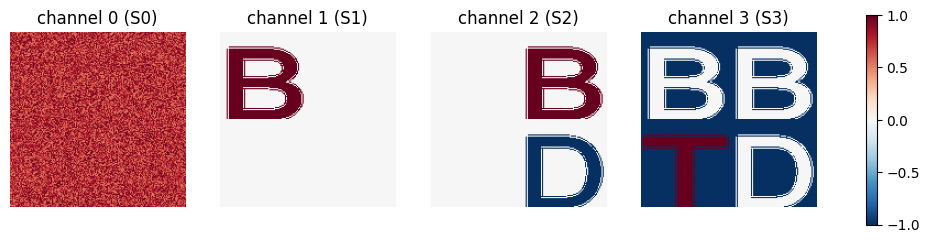

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for k, ax in enumerate(axes):
    im = ax.imshow(T[:, :, k], cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"channel {k} (S{k})")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

Each pixel's four numbers are its **Stokes vector**: total brightness (S0) and three numbers
describing how the light is polarized (S1, S2, S3). The four numbers at row 20, column 20,
inside the first letter B:

In [3]:
T[20, 20]

array([0.95958013, 1.        , 0.        , 0.        ])

## Decomposing a tensor

pyBBTD explains a tensor as a **sum of a few simple parts**, called *terms*. Each term is

- a **spatial map**: an image saying where the term is present, and
- a **signature**: the numbers the term puts in each pixel where it is present (here, one
  polarization state).

Every pixel's numbers are the sum, over the terms, of *map value × signature*. The image
above is made of five terms: the background and the four letters, each with its own
polarization. Recovering them from the data alone is what the
[Quickstart](quickstart.ipynb) does.

The figure below shows the same idea for covariance images, where each pixel holds a
matrix Σ(i, j): the image is a sum of maps **S**ᵣ, each paired with one matrix Σᵣ.

![A covariance image written as a sum of R spatial maps, each times one covariance matrix](../images/model_covll1.png)

## What you choose: R and L

- **R** is the number of terms (here, 5).
- **L** is the *rank* of each spatial map, a measure of how complex its shape can be. A map
  of rank 1 is a column profile times a row profile, such as a rectangle aligned with the
  image axes. A map of rank L is a sum of L such pieces, so letters need a higher rank than
  a rectangle.

## Next steps

- [Quickstart](quickstart.ipynb): decompose the image above in a few lines.
- [Choosing a model](../models/index.md): which model fits your data.
- [Glossary](../glossary.md): the vocabulary used in these pages.